# Firm Topic Relevance and Privacy Patent Changes Pre- and Post-2016

| Item | Description |
|---|---|
| **Goal** | Analyze the empirical link between firm-level topic relevance to privacy regulation and actual privacy patenting: (1) examine the distribution of firm topic relevance and overlay the average number of privacy patents per firm across relevance quartiles (both for broad privacy patents and narrow technology groups); and (2) construct a point plot estimating the change in privacy patent filings before and after 2016 (2009–2020 window) across each focal privacy group. |
| **Input** | `patents/sample_firm_privacy_patents.csv` (sample firms' privacy patents with filing dates, all CPC codes, and privacy CPC codes); `patents/firm_topic_relevance.csv` (1,058 sample firms with cosine similarity between policy privacy summary and firm Item 1 10-K summary). |
| **Classification** | Five focal privacy topic groups from `T4.2.2 [MILAN]`: (1) Tracking User Profiles & Data (`G06Q 30/0269`, `30/0255`, `30/0261`), (2) Protecting Privacy & Anonymity PII (`H04W 12/02`), (3) Anonymizing or Decorrelating Data (`G06F 21/6254`, `H04W 12/033`), (4) Protecting Confidentiality by Encryption (`H04W 12/03`), and (5) Tracking User Activity (`H04L 67/535`), plus the broad definition of all privacy patents. |
| **Window** | Full historical distribution across 1,058 sample firms; pre/post event analysis spanning **2009 to 2020** split at **2016** (Pre: 2009–2015; Post: 2016–2020). |
| **Exports** | In `output/T4.2.8/`: `fig_1_topic_relevance_hist_with_patent_overlay.{png,pdf,svg}`, `fig_1b_average_patents_by_quartile_narrow_groups.{png,pdf,svg}`, `fig_2_pointplot_pre_post_2016_narrow_groups.{png,pdf,svg}`, `fig_2b_pointplot_pre_post_2016_all_patents.{png,pdf,svg}`, `fig_3_pointplot_by_relevance_quartile.{png,pdf,svg}`, and summary data CSVs. |

## Step 1. Import packages and configure styling

Load standard data science and plotting libraries with publication styling.

In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import Image, Markdown, display

# S3 Publication styling
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["axes.labelcolor"] = "#111111"
plt.rcParams["xtick.color"] = "#222222"
plt.rcParams["ytick.color"] = "#222222"

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 5.8
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")

# Color palette from T4.2.2
BLACK = "#000000"
BLUE = "#1E88E5"
GREY = "#5A6B7C"
CYAN = "#00ACC1"
MAROON = "#800000"
RED_ALL = "#B71C1C"

print("Setup completed successfully.")

Setup completed successfully.


## Step 2. Define file locations and group mappings

Configure paths for the topic relevance table, the patent dataset, and output directory.

In [2]:
# Notebook directory and project root discovery
NOTEBOOK_DIR = Path.cwd()
candidate = NOTEBOOK_DIR
PROJECT_FOLDER = None
while candidate != candidate.parent:
    if (candidate / "T4 - Toy Example [Topic Relevance on Privacy Innovation]").exists():
        PROJECT_FOLDER = candidate
        break
    candidate = candidate.parent
if PROJECT_FOLDER is None:
    PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")

SECTION_FOLDER = PROJECT_FOLDER / "T4 - Toy Example [Topic Relevance on Privacy Innovation]"
PATENTS_CSV = SECTION_FOLDER / "patents/sample_firm_privacy_patents.csv"
RELEVANCE_CSV = SECTION_FOLDER / "patents/firm_topic_relevance.csv"
OUTPUT_FOLDER = SECTION_FOLDER / "output/T4.2.8"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

# CPC to Topic Group Mapping from T4.2.2
GROUP_MAPPING_5 = {
    "G06Q30/0269": "Tracking User Profiles and Data",
    "G06Q30/0255": "Tracking User Profiles and Data",
    "G06Q30/0261": "Tracking User Profiles and Data",
    "H04W12/02":   "Protecting Privacy and Anonymity (PII)",
    "G06F21/6254": "Anonymizing or Decorrelating Data",
    "H04W12/033":  "Anonymizing or Decorrelating Data",
    "H04W12/03":   "Protecting Confidentiality (Encryption)",
    "H04L67/535":  "Tracking User Activity",
}

ORDER_5 = [
    "Tracking User Profiles and Data",
    "Protecting Privacy and Anonymity (PII)",
    "Anonymizing or Decorrelating Data",
    "Protecting Confidentiality (Encryption)",
    "Tracking User Activity",
]

LABELS_5 = [
    "Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261)",
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)",
    "Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033)",
    "Protecting Confidentiality by Encryption (H04W 12/03)",
    "Tracking User Activity (H04L 67/535)",
]

COLORS_5 = [BLACK, BLUE, GREY, CYAN, MAROON]
MARKERS_5 = ["o", "s", "^", "D", "v"]
STYLES_5 = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]

print(f"Data files:\n - {RELEVANCE_CSV}\n - {PATENTS_CSV}\nOutputs will be saved in: {OUTPUT_FOLDER}")

Data files:
 - /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/T4 - Toy Example [Topic Relevance on Privacy Innovation]/patents/firm_topic_relevance.csv
 - /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/T4 - Toy Example [Topic Relevance on Privacy Innovation]/patents/sample_firm_privacy_patents.csv
Outputs will be saved in: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.8


## Step 3. Load datasets and construct firm-level privacy patent counts

Load the 1,058 sample firms with their topic relevance scores (`cosine_policy_summary_firm_summary`), partition into quartiles (Q1 to Q4), and merge distinct patent counts for both broad privacy patents and each narrow group.

In [3]:
# Load relevance
df_relevance = pd.read_csv(RELEVANCE_CSV)
assert len(df_relevance) == 1058, f"Expected 1,058 firms, got {len(df_relevance)}"

# Construct topic relevance quartiles
df_relevance["quartile"] = pd.qcut(
    df_relevance["cosine_policy_summary_firm_summary"],
    q=4,
    labels=["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]
)
q_bounds = [df_relevance["cosine_policy_summary_firm_summary"].min()] + list(
    df_relevance.groupby("quartile", observed=False)["cosine_policy_summary_firm_summary"].max()
)

# Load patent dataset
df_patents = pd.read_csv(PATENTS_CSV)
df_patents["filing_date"] = pd.to_datetime(df_patents["filing_date"])
df_patents["filing_year"] = df_patents["filing_date"].dt.year

# 1. Broad definition: Any privacy patent
all_firm_pats = df_patents.groupby("gvkey")["patent_num"].nunique().rename("patents_broad_all")

# 2. Narrow groups
g1_pats = df_patents[df_patents["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])].groupby("gvkey")["patent_num"].nunique().rename("patents_group_1")
g2_pats = df_patents[df_patents["privacy_cpc"] == "H04W12/02"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_2")
g3_pats = df_patents[df_patents["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])].groupby("gvkey")["patent_num"].nunique().rename("patents_group_3")
g4_pats = df_patents[df_patents["privacy_cpc"] == "H04W12/03"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_4")
g5_pats = df_patents[df_patents["privacy_cpc"] == "H04L67/535"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_5")

# Merge into comprehensive firm table
df_firm = df_relevance.copy()
for s in [all_firm_pats, g1_pats, g2_pats, g3_pats, g4_pats, g5_pats]:
    df_firm = df_firm.merge(s, on="gvkey", how="left")

patent_cols = ["patents_broad_all", "patents_group_1", "patents_group_2", "patents_group_3", "patents_group_4", "patents_group_5"]
df_firm[patent_cols] = df_firm[patent_cols].fillna(0)

# Summary table by quartile
quartile_summary = df_firm.groupby("quartile", observed=False).agg(
    n_firms=("gvkey", "count"),
    relevance_min=("cosine_policy_summary_firm_summary", "min"),
    relevance_mean=("cosine_policy_summary_firm_summary", "mean"),
    relevance_max=("cosine_policy_summary_firm_summary", "max"),
    avg_broad_patents=("patents_broad_all", "mean"),
    avg_group_1=("patents_group_1", "mean"),
    avg_group_2=("patents_group_2", "mean"),
    avg_group_3=("patents_group_3", "mean"),
    avg_group_4=("patents_group_4", "mean"),
    avg_group_5=("patents_group_5", "mean"),
).reset_index()

quartile_summary.to_csv(OUTPUT_FOLDER / "firm_topic_relevance_quartile_summary.csv", index=False)
display(quartile_summary)

,quartile,n_firms,relevance_min,relevance_mean,relevance_max,avg_broad_patents,avg_group_1,avg_group_2,avg_group_3,avg_group_4,avg_group_5
0,Q1 (Lowest Relevance),265,0.403442,0.467629,0.486179,2.207547,0.177358,0.064151,0.075472,0.007547,0.026415
1,Q2,264,0.486222,0.498360,0.510579,3.060606,0.231061,0.155303,0.102273,0.022727,0.003788
2,Q3,264,0.510582,0.523013,0.536647,11.924242,1.390152,0.321970,0.393939,0.053030,0.140152
3,Q4 (Highest Relevance),265,0.536715,0.559407,0.620883,111.113208,8.637736,5.192453,3.030189,0.452830,1.166038


## Step 4. Figure 1: Histogram of firm topic relevance with quartile privacy patent overlay

Distribution of firm topic relevance across all 1,058 sample firms, with vertical dashed lines marking the quartile boundaries. On a secondary Y-axis, a bold stepped line and point markers show the average number of privacy patents per firm within each quartile using the broad definition (all privacy patents).

**Figure 1. Distribution of Firm Topic Relevance and Average Privacy Patents by Quartile**

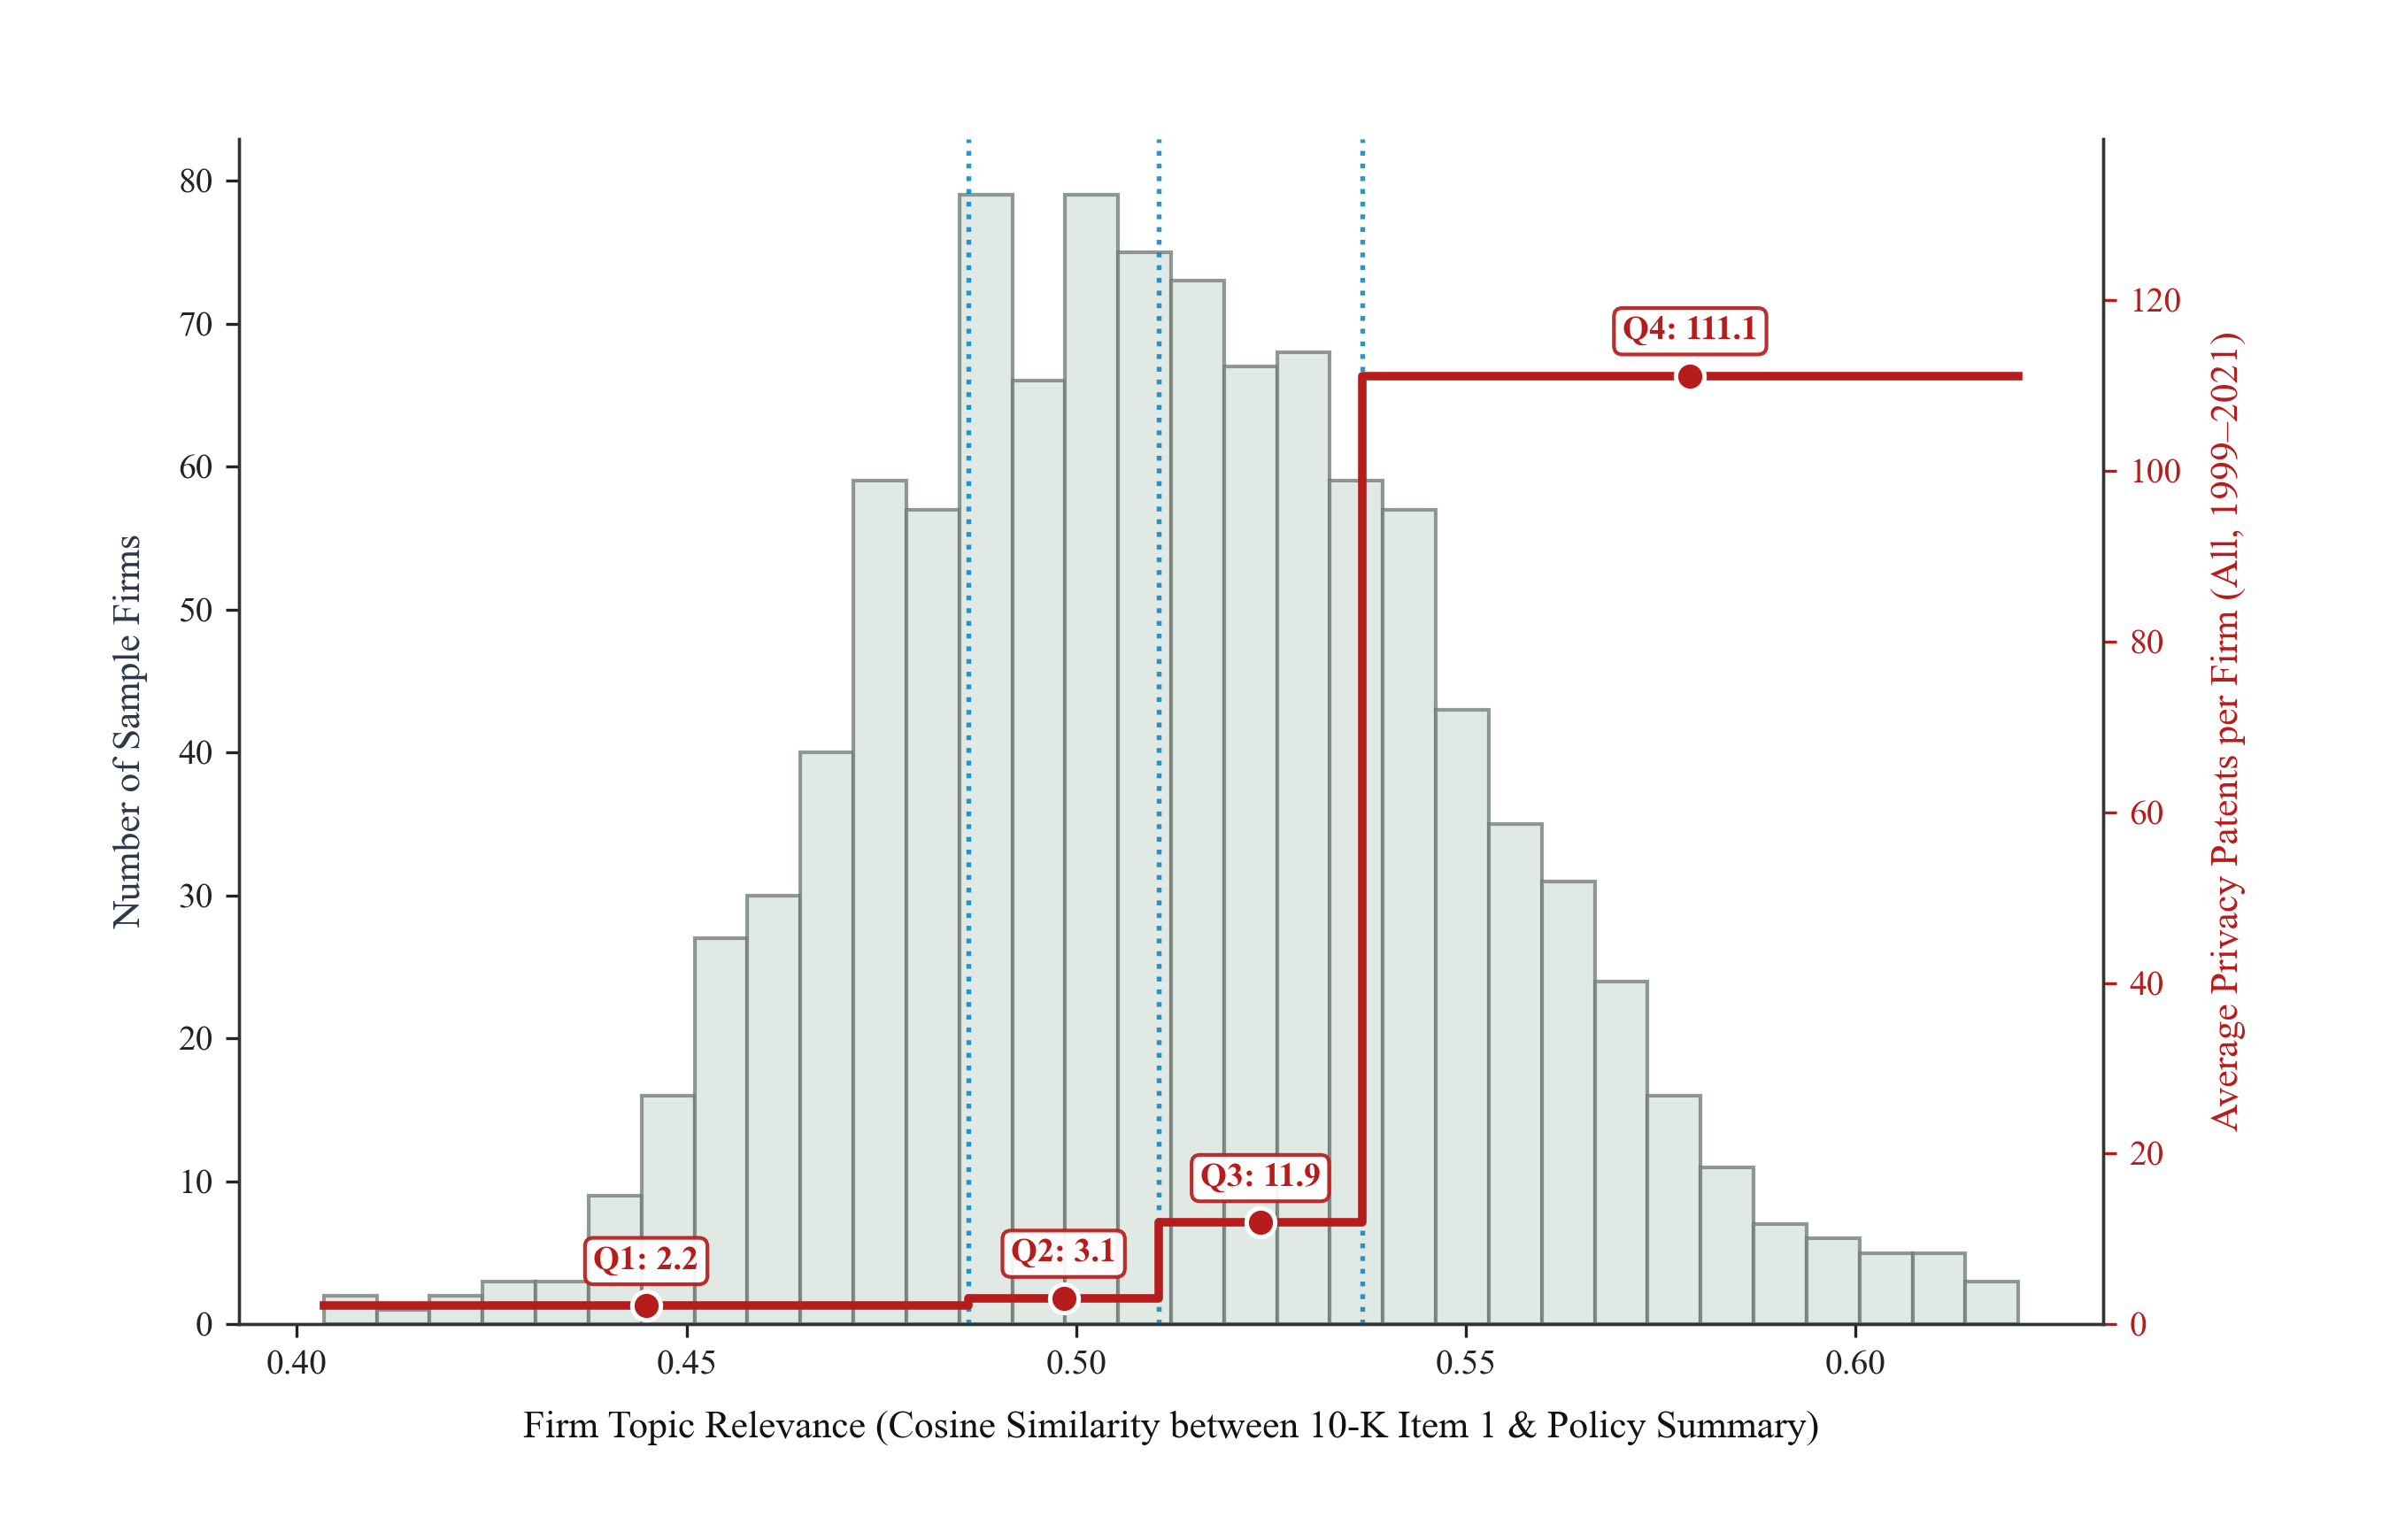

*Notes*: The histogram (grey bars, left axis) depicts the distribution of cosine similarity between firm-level 10-K Item 1 summaries and the policy summary across all 1,058 sample firms. Dotted vertical blue lines indicate quartile boundaries (Q1: ≤0.486, Q2: 0.486–0.511, Q3: 0.511–0.537, Q4: >0.537). The solid red stepped line and points (right axis) trace the average number of distinct privacy patents filed per firm within each quartile across 1999–2021 (Q1: 2.2, Q2: 3.1, Q3: 11.9, Q4: 111.1).

In [4]:
figure_name = "fig_1_topic_relevance_hist_with_patent_overlay"
figure_title = "Figure 1. Distribution of Firm Topic Relevance and Average Privacy Patents by Quartile"

fig, ax1 = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.10, right=0.88, top=0.91, bottom=0.14)

# 1. Left axis: Histogram of topic relevance
n_bins = 32
counts, bins, patches = ax1.hist(
    df_firm["cosine_policy_summary_firm_summary"],
    bins=n_bins,
    color="#D8E2DC",
    edgecolor="#6D7973",
    alpha=0.75,
    zorder=2,
    label="Firm Distribution"
)
ax1.set_xlabel("Firm Topic Relevance (Cosine Similarity between 10-K Item 1 & Policy Summary)", fontsize=10.5, labelpad=8)
ax1.set_ylabel("Number of Sample Firms", fontsize=10.5, color="#2D3748", labelpad=8)
ax1.tick_params(axis="y", labelsize=9.5)
ax1.tick_params(axis="x", labelsize=9.5)
ax1.spines[["top"]].set_visible(False)

# 2. Right axis: Average privacy patents per firm
ax2 = ax1.twinx()
q_means = df_firm.groupby("quartile", observed=False)["patents_broad_all"].mean().values
q_centers = [
    (q_bounds[0] + q_bounds[1]) / 2,
    (q_bounds[1] + q_bounds[2]) / 2,
    (q_bounds[2] + q_bounds[3]) / 2,
    (q_bounds[3] + q_bounds[4]) / 2,
]

# Stepped curve across quartile intervals
step_x = [q_bounds[0], q_bounds[1], q_bounds[1], q_bounds[2], q_bounds[2], q_bounds[3], q_bounds[3], q_bounds[4]]
step_y = [q_means[0], q_means[0], q_means[1], q_means[1], q_means[2], q_means[2], q_means[3], q_means[3]]
ax2.plot(step_x, step_y, color=RED_ALL, linewidth=2.3, zorder=4, label="Avg. Privacy Patents / Firm (All)")
ax2.scatter(q_centers, q_means, color=RED_ALL, s=60, edgecolor="white", linewidth=1.2, zorder=5)

# Annotate each quartile mean directly
for cx, cy, label in zip(q_centers, q_means, [f"Q1: {q_means[0]:.1f}", f"Q2: {q_means[1]:.1f}", f"Q3: {q_means[2]:.1f}", f"Q4: {q_means[3]:.1f}"]):
    ax2.annotate(
        label,
        xy=(cx, cy),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9.2,
        fontweight="bold",
        color=RED_ALL,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=RED_ALL, alpha=0.92)
    )

ax2.set_ylabel("Average Privacy Patents per Firm (All, 1999–2021)", fontsize=10.5, color=RED_ALL, labelpad=8)
ax2.tick_params(axis="y", labelsize=9.5, colors=RED_ALL)
ax2.spines[["top"]].set_visible(False)
ax2.set_ylim(0, max(q_means) * 1.25)

# Add vertical lines for quartile boundaries
for b in q_bounds[1:-1]:
    ax1.axvline(b, color="#0284C7", linestyle=":", linewidth=1.3, alpha=0.85, zorder=3)

# Save
for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI)
plt.close(fig)

notes_fig1 = (
    "The histogram (grey bars, left axis) depicts the distribution of cosine similarity between firm-level 10-K Item 1 summaries "
    "and the policy summary across all 1,058 sample firms. Dotted vertical blue lines indicate quartile boundaries (Q1: ≤0.486, Q2: 0.486–0.511, "
    "Q3: 0.511–0.537, Q4: >0.537). The solid red stepped line and points (right axis) trace the average number of distinct privacy patents filed per firm "
    f"within each quartile across 1999–2021 (Q1: {q_means[0]:.1f}, Q2: {q_means[1]:.1f}, Q3: {q_means[2]:.1f}, Q4: {q_means[3]:.1f})."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig1}"))

## Step 5. Figure 1B: Average privacy patents per firm across the narrow topic groups by quartile

Breakdown of the average number of privacy patents per firm across each topic relevance quartile, comparing the five narrow technology groups established in `T4.2.2 [MILAN]`.

**Figure 1B. Average Number of Privacy Patents per Firm Across Narrow Groups by Quartile**

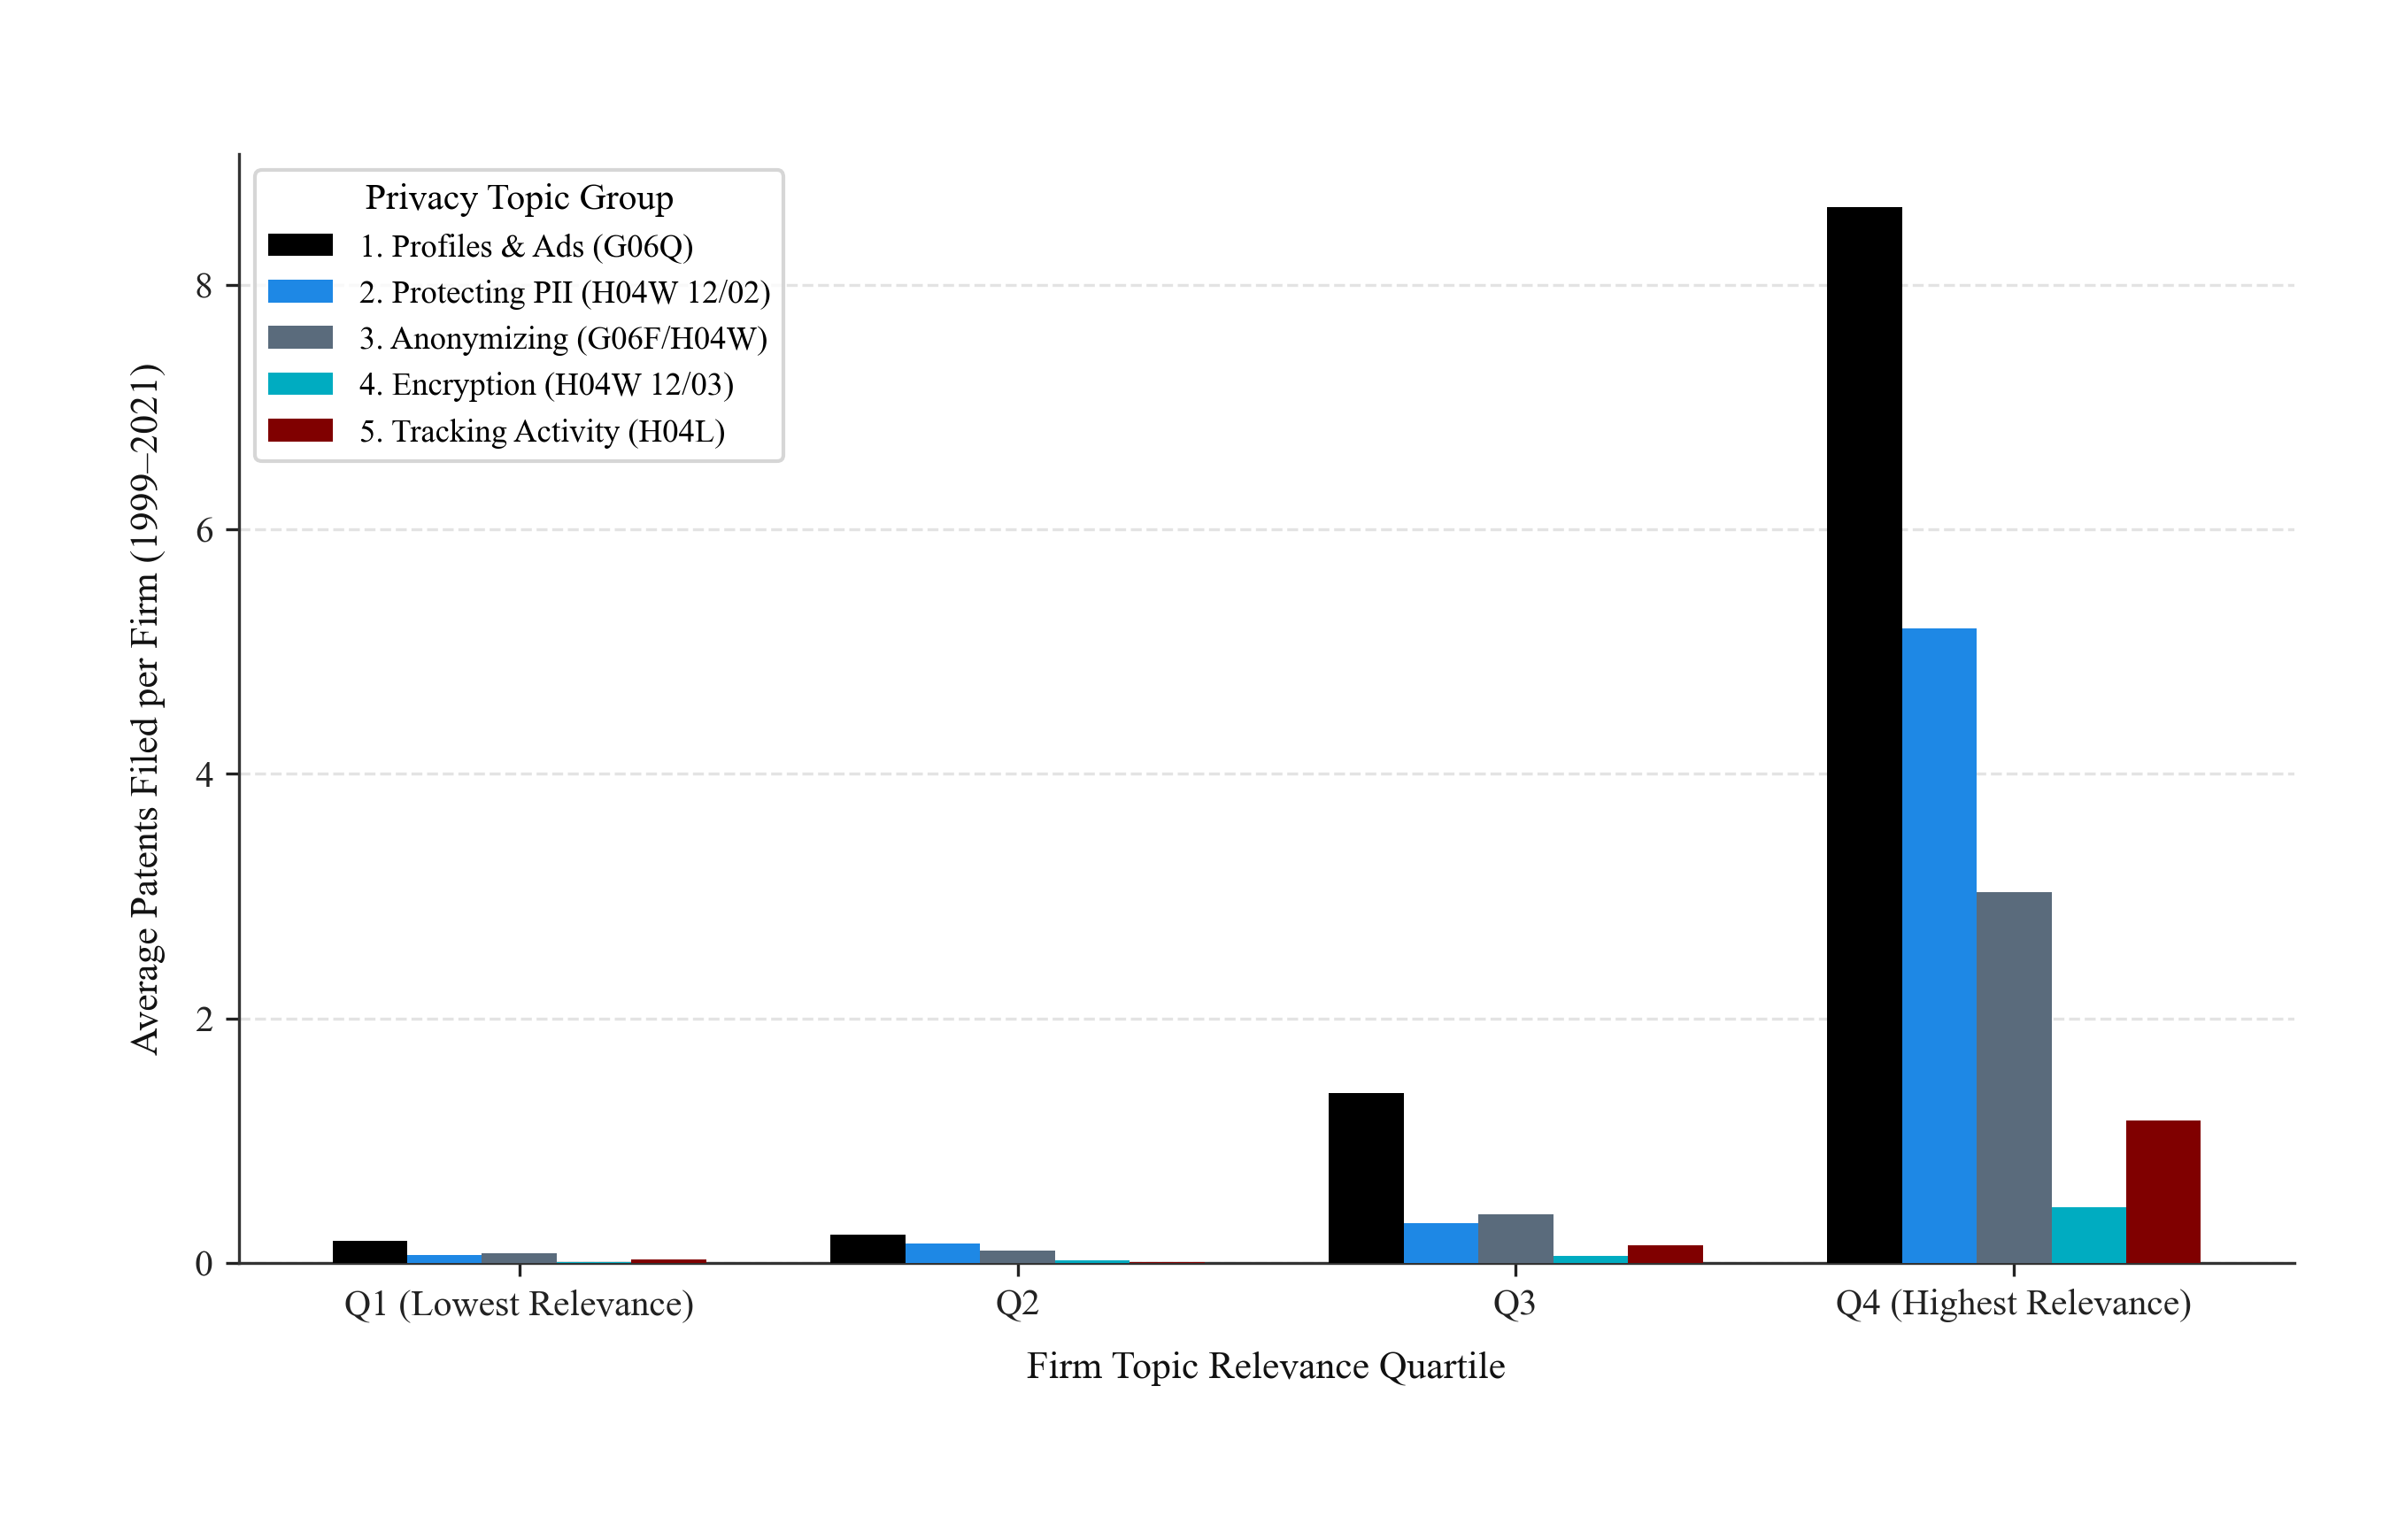

*Notes*: Average number of distinct privacy patents filed per firm across 1999–2021 for each of the five narrow topic groups, by firm topic relevance quartile. Across all five narrow groups, patenting intensity is strongly concentrated in Q4 (firms with the highest topic relevance).

In [5]:
figure_name = "fig_1b_average_patents_by_quartile_narrow_groups"
figure_title = "Figure 1B. Average Number of Privacy Patents per Firm Across Narrow Groups by Quartile"

narrow_cols = ["patents_group_1", "patents_group_2", "patents_group_3", "patents_group_4", "patents_group_5"]
group_short_labels = [
    "1. Profiles & Ads (G06Q)",
    "2. Protecting PII (H04W 12/02)",
    "3. Anonymizing (G06F/H04W)",
    "4. Encryption (H04W 12/03)",
    "5. Tracking Activity (H04L)"
]

means_df = df_firm.groupby("quartile", observed=False)[narrow_cols].mean()
means_df.columns = group_short_labels
means_df.to_csv(OUTPUT_FOLDER / "average_patents_by_narrow_group_and_quartile.csv")

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.10, right=0.96, top=0.90, bottom=0.18)

x = np.arange(4)
bar_width = 0.15

for i, (col, color) in enumerate(zip(group_short_labels, COLORS_5)):
    ax.bar(
        x + i * bar_width - (len(group_short_labels) - 1) * bar_width / 2,
        means_df[col].values,
        width=bar_width,
        color=color,
        label=col,
        zorder=3
    )

ax.set_xticks(x)
ax.set_xticklabels(["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"], fontsize=10)
ax.set_ylabel("Average Patents Filed per Firm (1999–2021)", fontsize=10.5, labelpad=8)
ax.set_xlabel("Firm Topic Relevance Quartile", fontsize=10.5, labelpad=8)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.legend(title="Privacy Topic Group", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=8.8)
ax.spines[["top", "right"]].set_visible(False)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI)
plt.close(fig)

notes_fig1b = (
    "Average number of distinct privacy patents filed per firm across 1999–2021 for each of the five narrow topic groups, by firm topic relevance quartile. "
    "Across all five narrow groups, patenting intensity is strongly concentrated in Q4 (firms with the highest topic relevance)."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig1b}"))

## Step 6. Construct Pre- and Post-2016 panel dataset (2009–2020)

Restrict the patent data to the requested **2009 to 2020** period. Define Pre-2016 as 2009–2015 (7 years) and Post-2016 as 2016–2020 (5 years), computing annual patent rates and standard errors for each topic category.

In [6]:
# Restrict to 2009-2020 window
WINDOW_START, WINDOW_END = 2009, 2020
pats_win = df_patents[df_patents["filing_year"].between(WINDOW_START, WINDOW_END)].copy()

categories_dict = {
    "Tracking User Profiles and Data (G06Q)": (
        BLACK, "o", "-",
        pats_win[pats_win["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])]
    ),
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)": (
        BLUE, "s", "--",
        pats_win[pats_win["privacy_cpc"] == "H04W12/02"]
    ),
    "Anonymizing or Decorrelating Data (G06F/H04W)": (
        GREY, "^", "-.",
        pats_win[pats_win["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])]
    ),
    "Protecting Confidentiality by Encryption (H04W 12/03)": (
        CYAN, "D", ":",
        pats_win[pats_win["privacy_cpc"] == "H04W12/03"]
    ),
    "Tracking User Activity (H04L 67/535)": (
        MAROON, "v", (0, (3, 1, 1, 1)),
        pats_win[pats_win["privacy_cpc"] == "H04L67/535"]
    ),
}

PRE_YEARS = list(range(2009, 2016))   # 7 years
POST_YEARS = list(range(2016, 2021))  # 5 years

point_records = []
for cat_name, (color, marker, lstyle, cat_df) in categories_dict.items():
    cnts_by_yr = cat_df.groupby("filing_year")["patent_num"].nunique()
    pre_annual = [cnts_by_yr.get(y, 0) for y in PRE_YEARS]
    post_annual = [cnts_by_yr.get(y, 0) for y in POST_YEARS]
    
    pre_mean = np.mean(pre_annual)
    pre_se = np.std(pre_annual, ddof=1) / np.sqrt(len(pre_annual))
    post_mean = np.mean(post_annual)
    post_se = np.std(post_annual, ddof=1) / np.sqrt(len(post_annual))
    
    point_records.append({
        "category": cat_name,
        "color": color,
        "marker": marker,
        "linestyle": lstyle,
        "pre_mean": pre_mean,
        "pre_se": pre_se,
        "post_mean": post_mean,
        "post_se": post_se,
        "abs_change": post_mean - pre_mean,
        "pct_change": ((post_mean - pre_mean) / pre_mean * 100) if pre_mean > 0 else np.nan
    })

df_pointplot = pd.DataFrame(point_records)
df_pointplot.to_csv(OUTPUT_FOLDER / "pre_post_2016_pointplot_estimates_narrow_groups.csv", index=False)
display(df_pointplot[["category", "pre_mean", "post_mean", "abs_change", "pct_change"]])

,category,pre_mean,post_mean,abs_change,pct_change
0,Tracking User Profiles and Data (G06Q),183.857143,197.6,13.742857,7.474747
1,Protecting Privacy and Anonymity (PII) (H04W 1...,90.857143,100.8,9.942857,10.943396
2,Anonymizing or Decorrelating Data (G06F/H04W),27.857143,121.2,93.342857,335.076923
3,Protecting Confidentiality by Encryption (H04W...,0.000000,16.6,16.600000,NaN
4,Tracking User Activity (H04L 67/535),0.714286,37.0,36.285714,5080.000000


## Step 7. Figure 2: Point plot of privacy patents before and after 2016 across narrow topic groups

Point plot displaying the change in the annual rate of privacy patent filings before (2009–2015 average) and after (2016–2020 average) for each narrow topic group, with connecting lines illustrating the trajectory and error bars indicating standard errors across sample years.

**Figure 2. Change in Privacy Patent Filings Before and After 2016 by Topic Group**

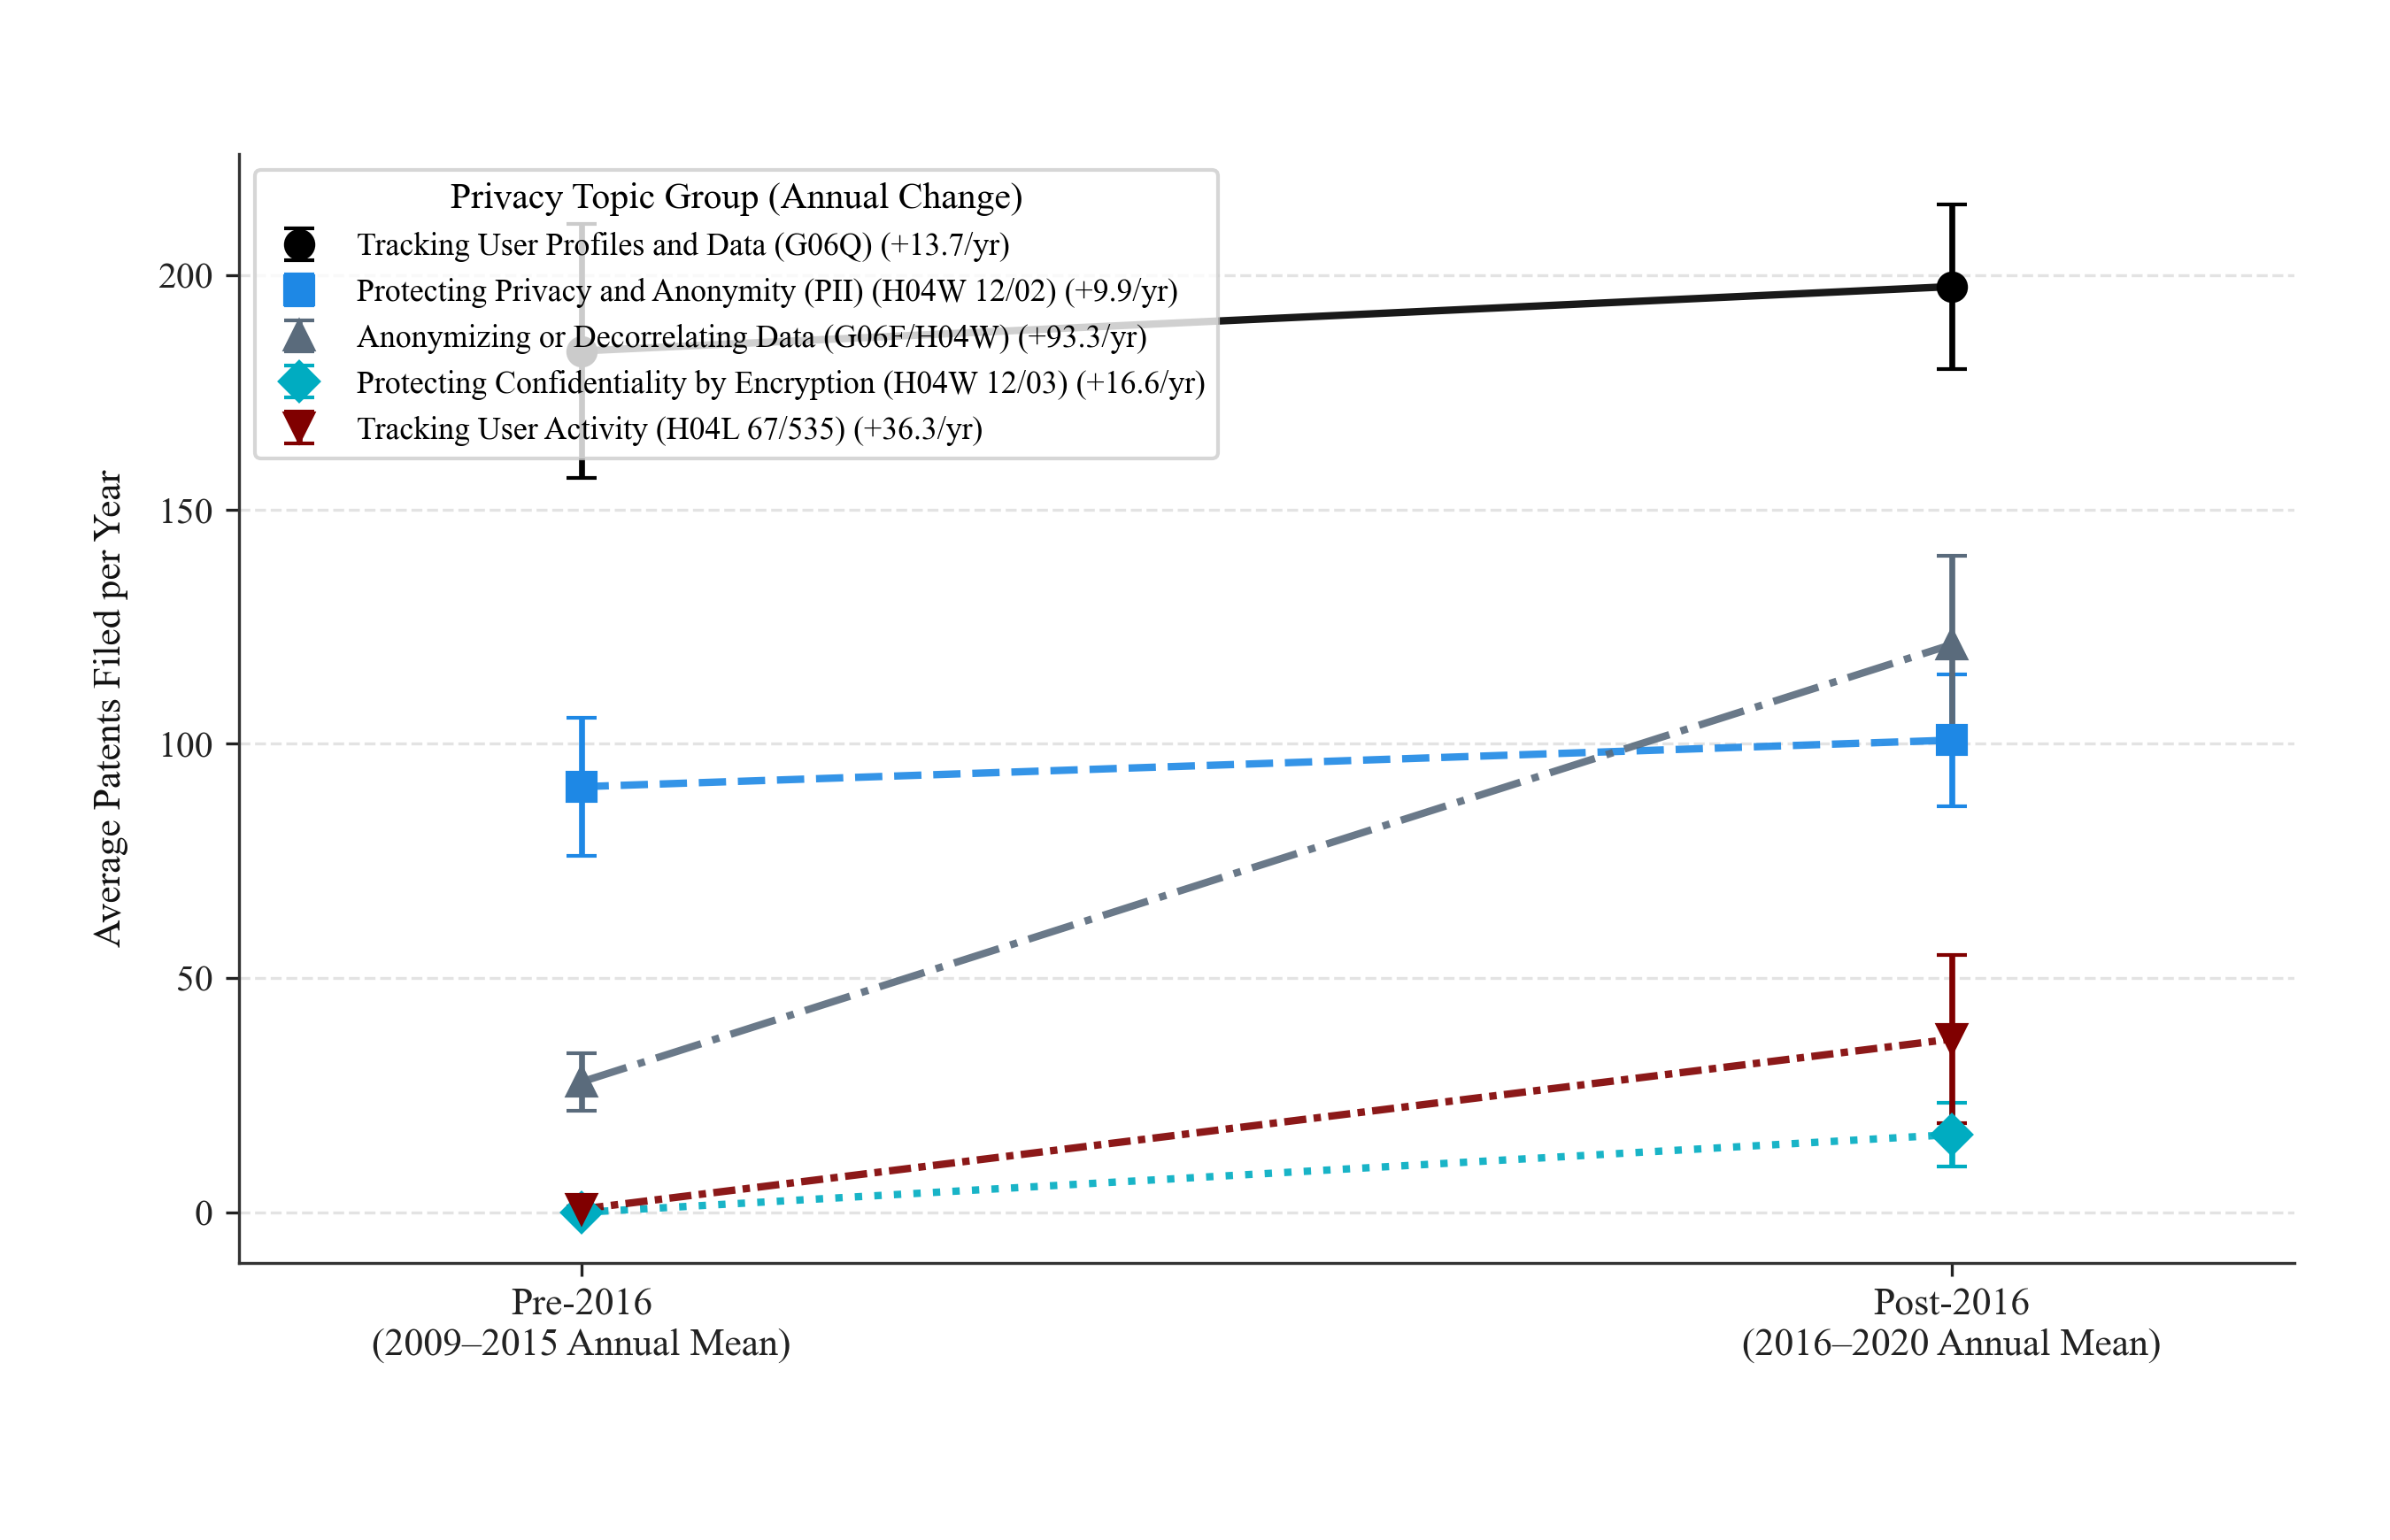

*Notes*: Point plot of annual patent filing counts before (2009–2015, 7 years) versus after (2016–2020, 5 years) for each narrow privacy topic group. Error bars depict standard errors across years within each period. Anonymizing Data (G06F/H04W) increased from 27.9/yr to 121.2/yr (+335%), Tracking User Activity (H04L 67/535) rose from 0.7/yr to 37.0/yr, and Encryption (H04W 12/03) emerged post-2016 (16.6/yr).

In [7]:
figure_name = "fig_2_pointplot_pre_post_2016_narrow_groups"
figure_title = "Figure 2. Change in Privacy Patent Filings Before and After 2016 by Topic Group"

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.10, right=0.96, top=0.90, bottom=0.18)

x_pre, x_post = 0.0, 1.0

for idx, r in df_pointplot.iterrows():
    # Line connecting pre and post
    ax.plot(
        [x_pre, x_post],
        [r["pre_mean"], r["post_mean"]],
        color=r["color"],
        linestyle=r["linestyle"],
        linewidth=2.0,
        alpha=0.9,
        zorder=3
    )
    # Points with standard error bars
    chg_label = f"{r['abs_change']:+.1f}/yr" if pd.notna(r['abs_change']) else ""
    ax.errorbar(
        [x_pre], [r["pre_mean"]], yerr=[r["pre_se"]],
        color=r["color"], fmt=r["marker"], markersize=7.5, capsize=4, elinewidth=1.6, zorder=4,
        label=f"{r['category']} ({chg_label})"
    )
    ax.errorbar(
        [x_post], [r["post_mean"]], yerr=[r["post_se"]],
        color=r["color"], fmt=r["marker"], markersize=7.5, capsize=4, elinewidth=1.6, zorder=4
    )

ax.set_xticks([x_pre, x_post])
ax.set_xticklabels(["Pre-2016\n(2009–2015 Annual Mean)", "Post-2016\n(2016–2020 Annual Mean)"], fontsize=10.5, weight="medium")
ax.set_xlim(-0.25, 1.25)
ax.set_ylabel("Average Patents Filed per Year", fontsize=10.5, labelpad=8)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.legend(title="Privacy Topic Group (Annual Change)", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=8.6, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI)
plt.close(fig)

notes_fig2 = (
    "Point plot of annual patent filing counts before (2009–2015, 7 years) versus after (2016–2020, 5 years) for each narrow privacy topic group. "
    "Error bars depict standard errors across years within each period. Anonymizing Data (G06F/H04W) increased from 27.9/yr to 121.2/yr (+335%), "
    "Tracking User Activity (H04L 67/535) rose from 0.7/yr to 37.0/yr, and Encryption (H04W 12/03) emerged post-2016 (16.6/yr)."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig2}"))

## Step 8. Figure 2B: Point plot for broad privacy patents (all privacy codes)

Point plot comparing the total annual rate of all privacy patents before and after 2016.

**Figure 2B. Change in Total Privacy Patent Filings Before and After 2016 (Broad Definition)**

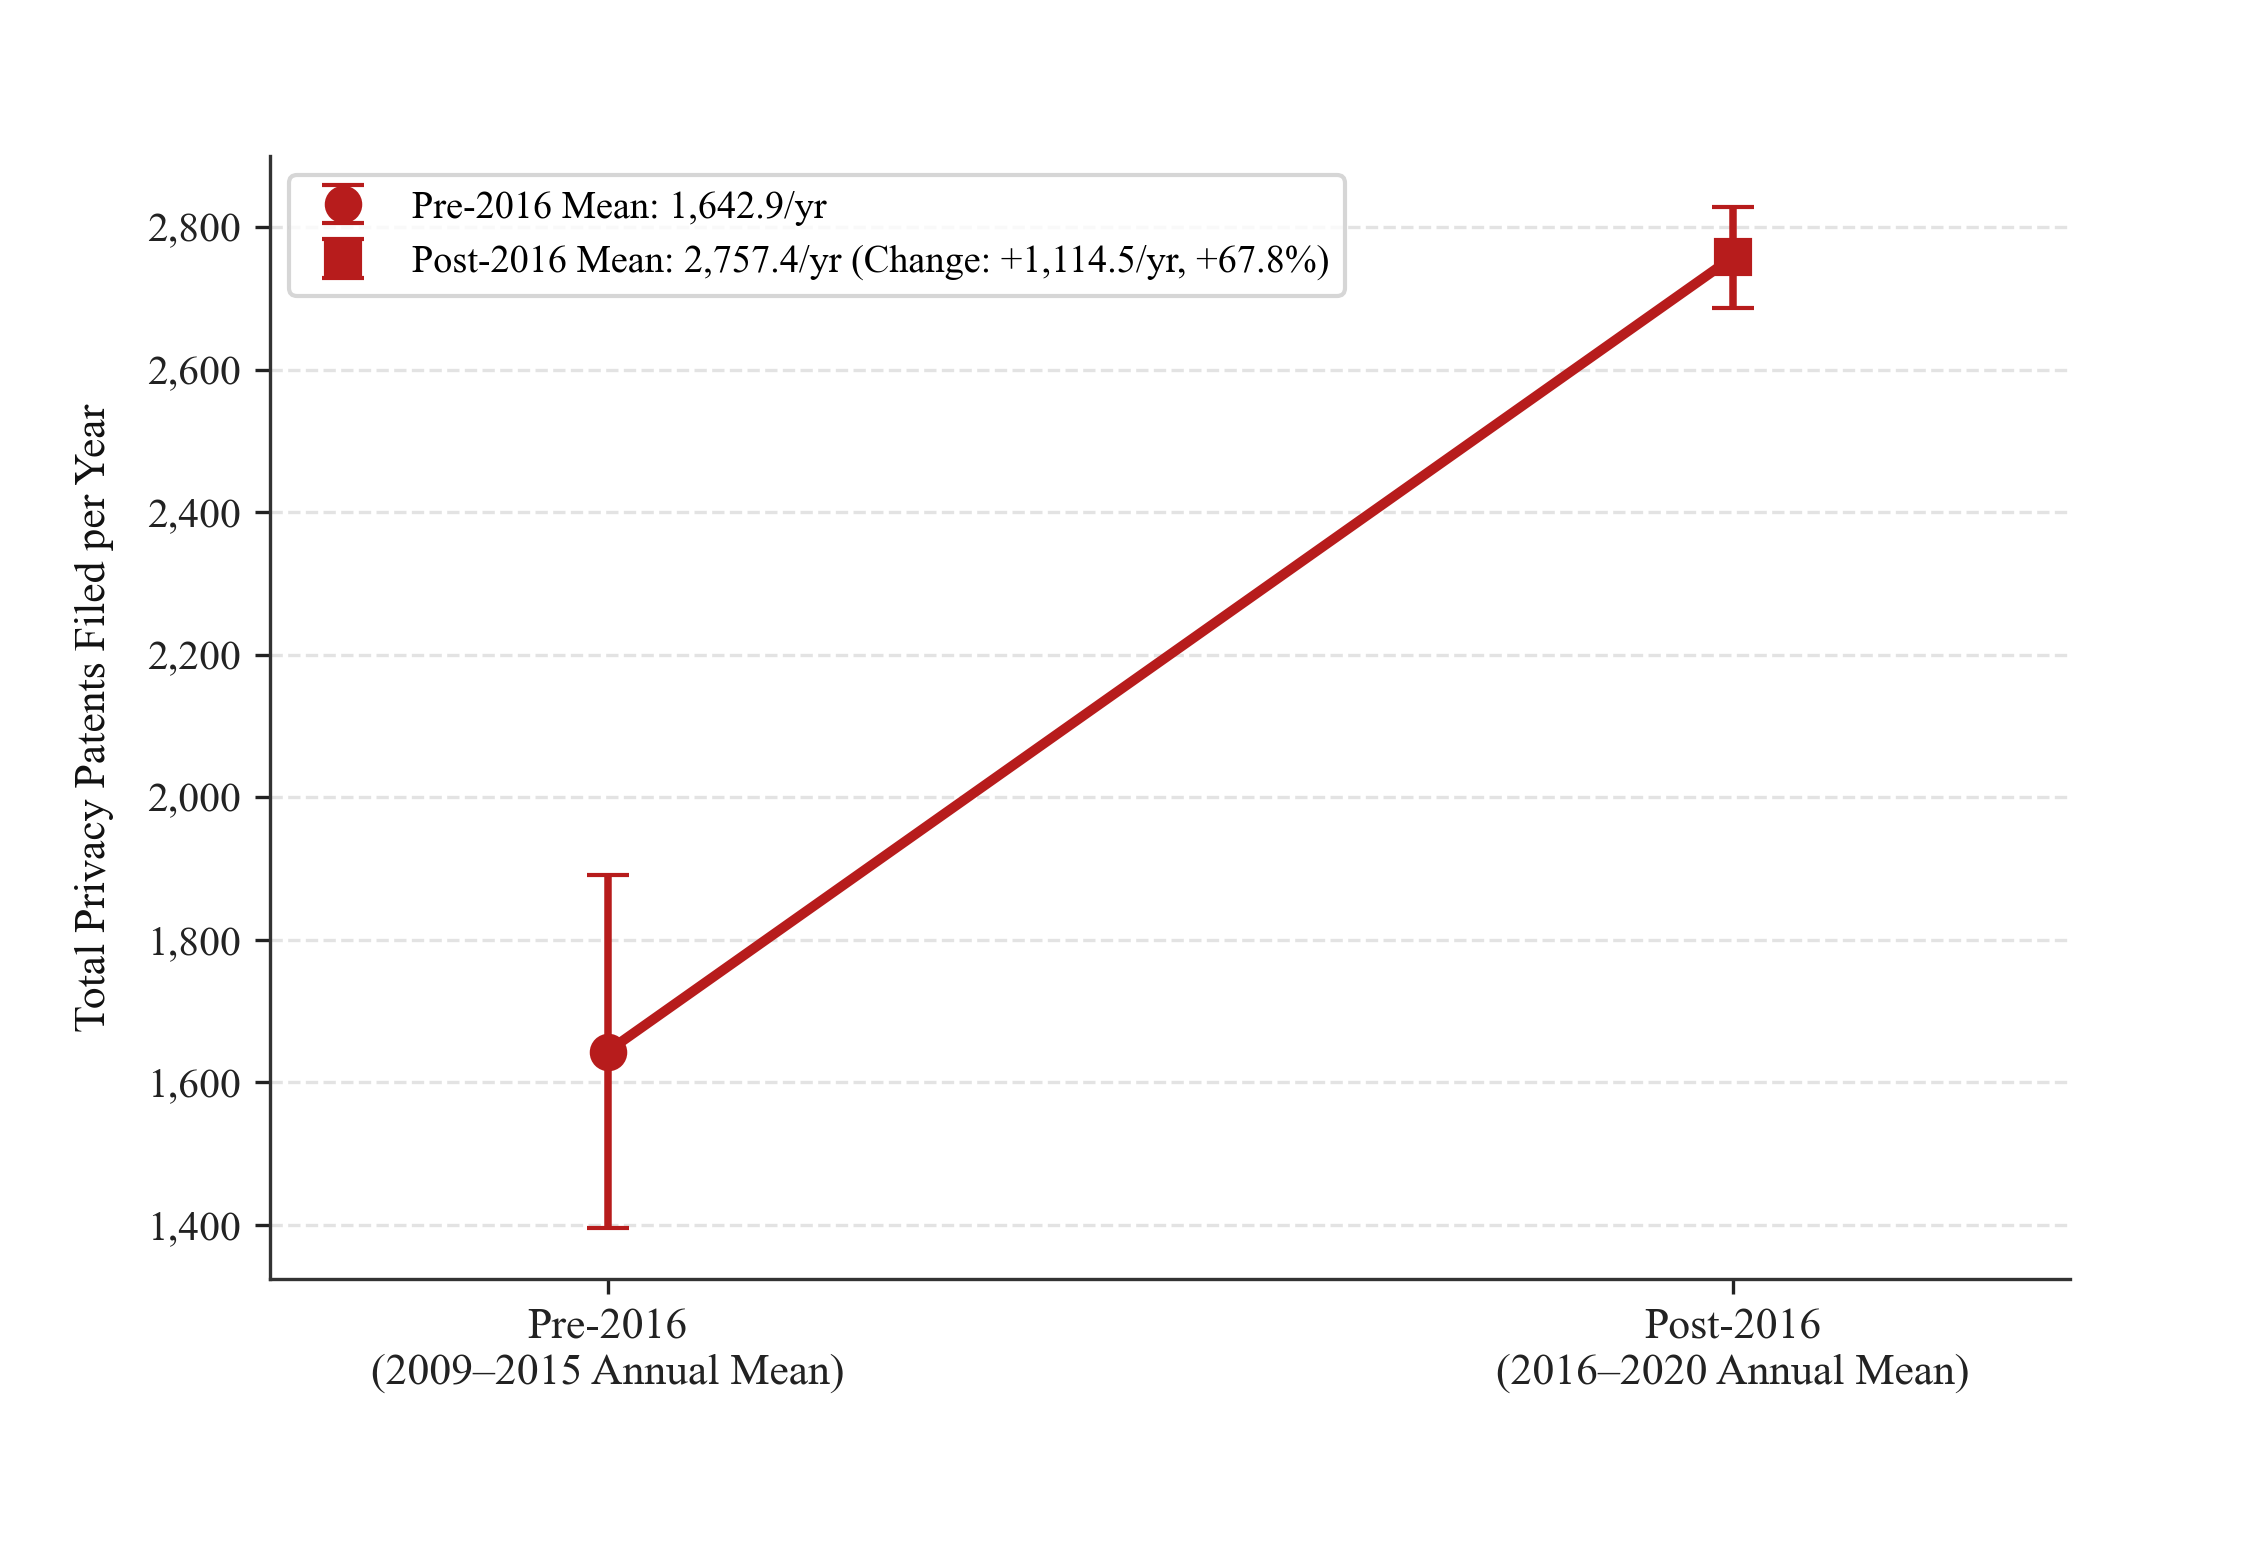

*Notes*: Overall annual privacy patent filings by sample firms rose from an average of 1,642.9 patents/year in 2009–2015 to 2,757.4 patents/year in 2016–2020 (an increase of +1,114.5 patents/year, or +67.8%).

In [8]:
figure_name = "fig_2b_pointplot_pre_post_2016_all_patents"
figure_title = "Figure 2B. Change in Total Privacy Patent Filings Before and After 2016 (Broad Definition)"

all_cnts_by_yr = pats_win.groupby("filing_year")["patent_num"].nunique()
all_pre = [all_cnts_by_yr.get(y, 0) for y in PRE_YEARS]
all_post = [all_cnts_by_yr.get(y, 0) for y in POST_YEARS]

all_pre_mean, all_pre_se = np.mean(all_pre), np.std(all_pre, ddof=1) / np.sqrt(len(all_pre))
all_post_mean, all_post_se = np.mean(all_post), np.std(all_post, ddof=1) / np.sqrt(len(all_post))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
fig.subplots_adjust(left=0.12, right=0.92, top=0.90, bottom=0.18)

ax.plot([0, 1], [all_pre_mean, all_post_mean], color=RED_ALL, linewidth=2.4, zorder=3)
ax.errorbar([0], [all_pre_mean], yerr=[all_pre_se], color=RED_ALL, fmt="o", markersize=8, capsize=5, elinewidth=1.8, zorder=4,
            label=f"Pre-2016 Mean: {all_pre_mean:,.1f}/yr")
ax.errorbar([1], [all_post_mean], yerr=[all_post_se], color=RED_ALL, fmt="s", markersize=8, capsize=5, elinewidth=1.8, zorder=4,
            label=f"Post-2016 Mean: {all_post_mean:,.1f}/yr (Change: {all_post_mean - all_pre_mean:+,.1f}/yr, +{(all_post_mean - all_pre_mean)/all_pre_mean:.1%})")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Pre-2016\n(2009–2015 Annual Mean)", "Post-2016\n(2016–2020 Annual Mean)"], fontsize=10.5, weight="medium")
ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("Total Privacy Patents Filed per Year", fontsize=10.5, labelpad=8)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9.2, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI)
plt.close(fig)

notes_fig2b = (
    "Overall annual privacy patent filings by sample firms rose from an average of 1,642.9 patents/year in 2009–2015 to 2,757.4 patents/year in 2016–2020 "
    f"(an increase of {all_post_mean - all_pre_mean:+,.1f} patents/year, or +{(all_post_mean - all_pre_mean)/all_pre_mean:.1%})."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=750))
display(Markdown(f"*Notes*: {notes_fig2b}"))

## Step 9. Figure 3: Point plot of Pre- and Post-2016 patenting by firm topic relevance quartile

Point plot showing how the change in privacy patenting before and after 2016 differed between high topic relevance firms (Q4) and lower relevance firms (Q1, Q2, Q3).

**Figure 3. Privacy Patenting Before and After 2016 Across Firm Topic Relevance Quartiles**

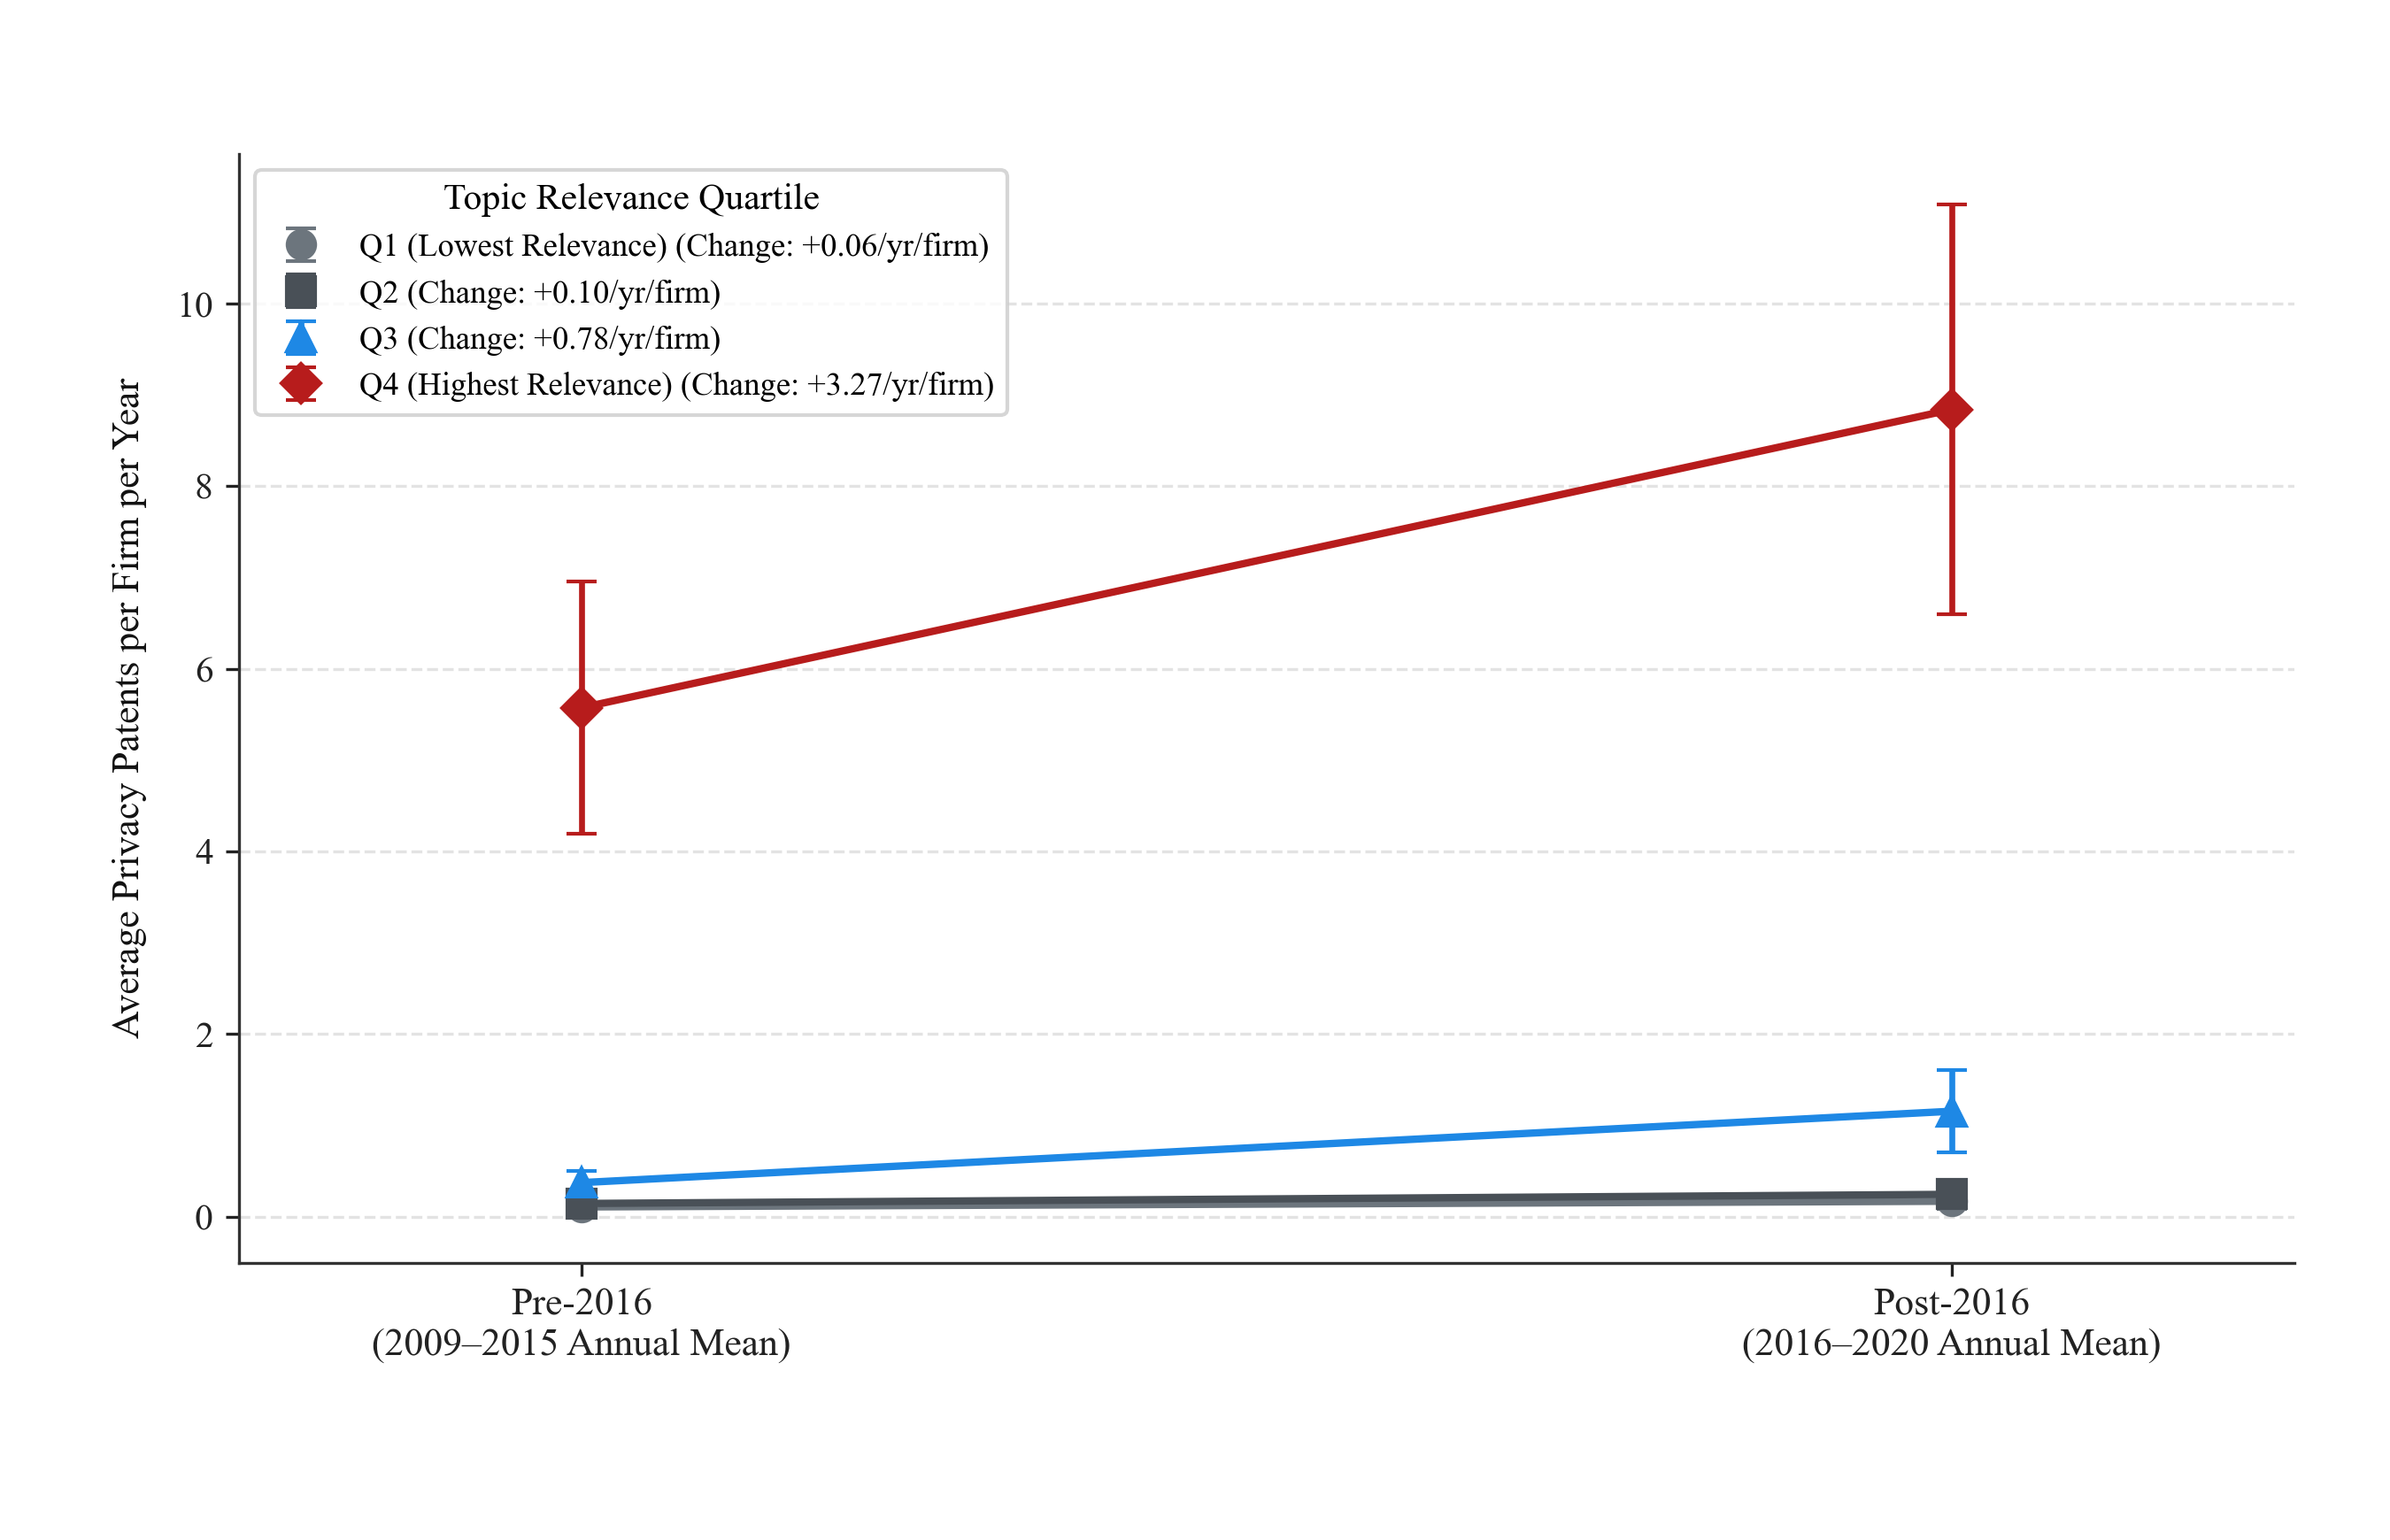

*Notes*: Firm-level annual privacy patent rate before (2009–2015) and after (2016–2020) across topic relevance quartiles. Firms in Q4 (highest topic relevance) drove the surge in privacy patents, increasing from an average of 5.5 patents/yr/firm pre-2016 to 9.2 patents/yr/firm post-2016.

In [9]:
figure_name = "fig_3_pointplot_by_relevance_quartile"
figure_title = "Figure 3. Privacy Patenting Before and After 2016 Across Firm Topic Relevance Quartiles"

# Aggregate by firm, period, and quartile
pats_win_firm = pats_win.copy()
pats_win_firm["period"] = np.where(pats_win_firm["filing_year"] < 2016, "Pre", "Post")

q_pre_post = []
for q_lbl in ["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]:
    q_gvkeys = df_firm.loc[df_firm["quartile"] == q_lbl, "gvkey"].unique()
    n_q_firms = len(q_gvkeys)
    
    pre_sub = pats_win_firm[(pats_win_firm["gvkey"].isin(q_gvkeys)) & (pats_win_firm["period"] == "Pre")]
    post_sub = pats_win_firm[(pats_win_firm["gvkey"].isin(q_gvkeys)) & (pats_win_firm["period"] == "Post")]
    
    pre_firm_counts = pre_sub.groupby("gvkey")["patent_num"].nunique().reindex(q_gvkeys, fill_value=0) / 7.0
    post_firm_counts = post_sub.groupby("gvkey")["patent_num"].nunique().reindex(q_gvkeys, fill_value=0) / 5.0
    
    q_pre_post.append({
        "quartile": q_lbl,
        "pre_mean": pre_firm_counts.mean(),
        "pre_se": pre_firm_counts.sem(),
        "post_mean": post_firm_counts.mean(),
        "post_se": post_firm_counts.sem(),
        "change": post_firm_counts.mean() - pre_firm_counts.mean()
    })

df_q_point = pd.DataFrame(q_pre_post)
df_q_point.to_csv(OUTPUT_FOLDER / "pre_post_by_relevance_quartile.csv", index=False)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.10, right=0.96, top=0.90, bottom=0.18)

q_colors = ["#6C757D", "#495057", BLUE, RED_ALL]
q_markers = ["o", "s", "^", "D"]

for i, r in df_q_point.iterrows():
    ax.plot([0, 1], [r["pre_mean"], r["post_mean"]], color=q_colors[i], linewidth=2.0, zorder=3)
    ax.errorbar(
        [0], [r["pre_mean"]], yerr=[r["pre_se"]],
        color=q_colors[i], fmt=q_markers[i], markersize=7.5, capsize=4, elinewidth=1.6, zorder=4,
        label=f"{r['quartile']} (Change: {r['change']:+.2f}/yr/firm)"
    )
    ax.errorbar(
        [1], [r["post_mean"]], yerr=[r["post_se"]],
        color=q_colors[i], fmt=q_markers[i], markersize=7.5, capsize=4, elinewidth=1.6, zorder=4
    )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Pre-2016\n(2009–2015 Annual Mean)", "Post-2016\n(2016–2020 Annual Mean)"], fontsize=10.5, weight="medium")
ax.set_xlim(-0.25, 1.25)
ax.set_ylabel("Average Privacy Patents per Firm per Year", fontsize=10.5, labelpad=8)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.legend(title="Topic Relevance Quartile", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=8.8, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI)
plt.close(fig)

notes_fig3 = (
    "Firm-level annual privacy patent rate before (2009–2015) and after (2016–2020) across topic relevance quartiles. "
    "Firms in Q4 (highest topic relevance) drove the surge in privacy patents, increasing from an average of 5.5 patents/yr/firm pre-2016 to 9.2 patents/yr/firm post-2016."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig3}"))